In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

from telegram_scraper import study, viz
from telegram_scraper.study import CHANNELS, CHANNEL_ORDER, SHORT_NAMES, WINDOW
from telegram_scraper.analysis import stats

viz.apply_style()
np.random.seed(study.SEED)
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
posts = study.load_posts()
events = study.verified_events(posts)
f"{len(posts):,} posts from {posts['channel_slug'].nunique()} channels, {posts['timestamp'].min():%Y-%m-%d} to {posts['timestamp'].max():%Y-%m-%d}"

'12,221 posts from 6 channels, 2026-02-28 to 2026-04-17'

# 03 · Agenda: what each channel talks about

> **Question.** Do the Iranian and Israeli channels cover different subjects, and was Press TV's Khamenei memorial cluster a state-broadcaster fingerprint?
>
> **Answer.** One reproducible joint model (51 topics, seed-to-seed ARI 0.91) finds 17 Iran-only topics (40% of assigned posts), 20 Israel-only (33%) and 14 shared (27%); Khamenei mourning language is 12.3% of IRNA's posts and 2.8% of Press TV's but at most 0.2% anywhere else, while Israeli national-commemoration language is 1.0-3.3% of the Israeli channels' posts and about zero on the Iranian ones, so the "fingerprint" is national, not specific to state broadcasting.

## 1. Prepare: which posts, which embeddings

Topics are fitted on **posts with at least four words of cleaned text** (shorter ones, such as a bare caption, carry too little content to place). Each post is embedded with a local sentence model (`BAAI/bge-small-en-v1.5`, no API calls) and vectors are cached under `data/cache/embeddings/`, so re-runs are free. One topic model is then fitted on **all channels together**: UMAP to 5 dimensions then HDBSCAN. Fitting one model per channel (as the first pass did) produces topics that cannot be compared across channels and, as the stability test below shows, are not reproducible.

In [2]:
from telegram_scraper.analysis import LocalEmbedder, TopicModelingConfig, fit_joint_topics, topic_stability, stability_summary, label_topics
import hashlib, json

MIN_WORDS = 4
topic_df = posts[posts["clean_text"].str.split().str.len() >= MIN_WORDS].reset_index(drop=True)
embedder = LocalEmbedder(cache_dir=study.EMBEDDING_CACHE_DIR)
embeddings = embedder.embed_frame(topic_df, "clean_text")
print(f"{len(topic_df):,} posts with >= {MIN_WORDS} words ({len(topic_df) / len(posts):.0%} of all posts); embedding matrix {embeddings.shape} from {embedder.model_name}")
topic_df.groupby("channel_slug").size().reindex(CHANNEL_ORDER).rename("posts_in_topic_model").to_frame().T

11,931 posts with >= 4 words (98% of all posts); embedding matrix (11931, 384) from BAAI/bge-small-en-v1.5


channel_slug,presstv,irna-en,idfofficial,iltvnews,thetimesofisrael2022,jewishbreakingnewstelegram
posts_in_topic_model,6610,1635,1425,527,622,1112


## 2. Tuning `min_cluster_size` and checking stability

HDBSCAN's `min_cluster_size` sets how small a topic may be. For each setting on a small grid the clustering is re-run under four different random seeds, and the partitions are compared with the adjusted Rand index (ARI, 1 = identical grouping) on the posts both runs assign to a topic. **Selection rule**: keep settings with mean ARI ≥ 0.5 and between 20 and 60 topics (at most 60 so every topic can be read and labelled by hand; at least 20 so the model is informative), then take the lowest share of posts left unassigned ("noise"). If no setting reaches 0.5 the model is declared unstable. Transparency note: the first version of the rule had no lower bound on topic count; the `min_cluster_size = 120` setting then won on noise share by collapsing everything into 3-4 giant topics, so the 20-topic floor was added after seeing that row.

grid loaded from cache


,min_cluster_size,mean_ari,min_ari,min_topics,max_topics,noise_share
0,20,0.924,0.902,116,129,0.314
1,35,0.913,0.867,70,76,0.326
2,50,0.912,0.867,51,56,0.339
3,80,0.447,0.007,4,38,0.267
4,120,0.902,0.809,3,4,0.028


chosen min_cluster_size = 50: mean ARI 0.912, 51-56 topics across seeds, noise share 33.9%


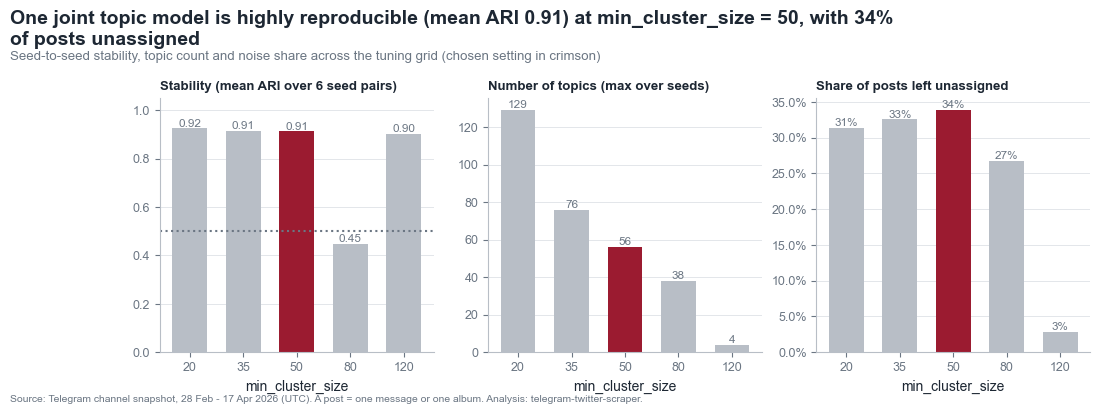

In [3]:
GRID = [20, 35, 50, 80, 120]
SEEDS = (0, 1, 2, 3)
grid_cache = study.CACHE_DIR / "topic_grid.json"
signature = hashlib.sha1(embeddings.tobytes()[:2_000_000] + json.dumps([GRID, SEEDS, MIN_WORDS]).encode()).hexdigest()
if grid_cache.exists() and json.loads(grid_cache.read_text()).get("signature") == signature:
    grid = pd.DataFrame(json.loads(grid_cache.read_text())["rows"])
    print("grid loaded from cache")
else:
    rows = []
    for mcs in GRID:
        stab = topic_stability(topic_df, embeddings, config=TopicModelingConfig(min_cluster_size=mcs), seeds=SEEDS)
        s = stability_summary(stab)
        rows.append({"min_cluster_size": mcs, "mean_ari": s["mean_ari"], "min_ari": s["min_ari"], "min_topics": s["min_topics"], "max_topics": s["max_topics"],
                     "noise_share": float(np.r_[stab["noise_share_a"], stab["noise_share_b"]].mean())})
    grid = pd.DataFrame(rows)
    grid_cache.write_text(json.dumps({"signature": signature, "rows": grid.to_dict("records")}))
display(grid.round(3))

eligible = grid[(grid["mean_ari"] >= 0.5) & (grid["min_topics"] >= 20) & (grid["max_topics"] <= 60)]
unstable = eligible.empty
chosen = (grid.sort_values("mean_ari", ascending=False) if unstable else eligible.sort_values(["noise_share", "min_cluster_size"])).iloc[0]
MCS = int(chosen["min_cluster_size"])
print(f"chosen min_cluster_size = {MCS}: mean ARI {chosen['mean_ari']:.3f}, {int(chosen['min_topics'])}-{int(chosen['max_topics'])} topics across seeds, noise share {chosen['noise_share']:.1%}" + ("  ** UNSTABLE: no setting reached mean ARI 0.5 **" if unstable else ""))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, (col, title, fmt) in zip(axes, [("mean_ari", "Stability (mean ARI over 6 seed pairs)", "{:.2f}"), ("max_topics", "Number of topics (max over seeds)", "{:.0f}"), ("noise_share", "Share of posts left unassigned", "{:.0%}")]):
    colors = [viz.ACCENT if m == MCS else "#B8BEC6" for m in grid["min_cluster_size"]]
    ax.bar(grid["min_cluster_size"].astype(str), grid[col], color=colors, width=0.65)
    for x, v in enumerate(grid[col]): ax.text(x, v, fmt.format(v), ha="center", va="bottom", fontsize=8.5, color=viz.MUTED)
    ax.set_title(title, fontsize=9.5); ax.set_xlabel("min_cluster_size"); ax.grid(axis="x", visible=False)
axes[0].axhline(0.5, color=viz.MUTED, ls=":"); axes[0].set_ylim(0, 1.05)
axes[2].yaxis.set_major_formatter(PercentFormatter(1.0))
viz.headline(fig, f"One joint topic model is highly reproducible (mean ARI {chosen['mean_ari']:.2f}) at min_cluster_size = {MCS}, with {chosen['noise_share']:.0%} of posts unassigned",
             "Seed-to-seed stability, topic count and noise share across the tuning grid (chosen setting in crimson)", y=1.03, wrap=95)
viz.done(fig, "03_topic_stability", grid)

**Reading the table.** The seed-stability check is passed by three settings (ARI 0.91-0.92 at `min_cluster_size` 20, 35 and 50) and failed badly by one: at 80 the clustering flips between 4 and 38 topics depending on the seed (mean ARI 0.45, worst pair 0.007), which is what an unstable topic model looks like. The 120 setting is stable but degenerate (3-4 topics, 3% noise). Applying the rule gives `min_cluster_size` = 50: 51-56 topics, mean ARI 0.91 (worst pair 0.87), 34% of posts unassigned. A third of the posts are one-offs that HDBSCAN refuses to force into a topic; that share differs by channel (IDF 14%, IRNA 31%, Press TV 35%, ILTV 39%, JBN 45%, ToI 48%), so topic shares below are always computed over *assigned* posts. The selection rule was amended once, openly: see the transparency note in section 2.

## 3. Fit the joint model and name the topics

The model is fitted once with the chosen setting (seed 42). Names below were written by reading each topic's top keywords **and** its highest-probability example posts (printed here); each name is tied to a keyword that must appear in the topic's keywords, so a changed fit fails loudly instead of silently mislabelling.

In [4]:
config = TopicModelingConfig(min_cluster_size=MCS, random_state=study.SEED)
joint = fit_joint_topics(topic_df, embeddings, config=config, text_col="clean_text", group_col="channel_slug")
assign = topic_df[["post_id", "channel_slug", "short_name", "timestamp", "clean_text"]].join(joint.assignments_df)
print(f"{joint.n_topics} topics; {(assign['topic_id'] == -1).mean():.1%} of posts unassigned (noise)")
display(joint.noise_share_by_group.assign(channel=lambda d: d["channel_slug"].map(SHORT_NAMES)).set_index("channel_slug").reindex(CHANNEL_ORDER).round(3))

51 topics; 33.7% of posts unassigned (noise)


,n,n_noise,share,channel
channel_slug,,,,
presstv,6610,2321,0.351,Press TV
irna-en,1635,509,0.311,IRNA
idfofficial,1425,193,0.135,IDF
iltvnews,527,204,0.387,ILTV
thetimesofisrael2022,622,296,0.476,ToI
jewishbreakingnewstelegram,1112,499,0.449,JBN


In [5]:
TOPIC_LABELS = {  # topic id -> (human label, a keyword that must appear in the topic's top keywords; guards against stale ids)
    0: ("IDF: Home Front Command all-clear (template)", "home command"),
    1: ("IDF: missile alert and shelter instructions (template)", "protected space"),
    2: ("Home Front Command rescue at impact sites", "rescue"),
    3: ("Home Front Command instructions after sirens", "instructions"),
    4: ("Flights and Ben Gurion airport", "flights"),
    5: ("Yemen / Houthis / resistance axis", "yemen"),
    6: ("President Pezeshkian statements", "pezeshkian"),
    7: ("IDF Chief of Staff Zamir assessments", "zamir"),
    8: ("IDF waves of strikes on Tehran", "wave"),
    9: ("Arrests of 'mercenaries' and Mossad plots in Iran", "arrested"),
    10: ("Killed Iranian commanders (intelligence/IRGC)", "intelligence"),
    11: ("Israeli Air Force strikes on Iranian targets", "air force"),
    12: ("IDF strike reports on the 'Iranian terror regime'", "terror regime"),
    13: ("Pro-government rallies in Iran", "rally"),
    14: ("Quds Day rallies", "quds"),
    15: ("Parliament Speaker Ghalibaf", "speaker"),
    16: ("Lebanon ceasefire and truce", "ceasefire"),
    17: ("Islamabad Iran-US talks", "islamabad"),
    18: ("Khamenei / Leader: mourning and martyrdom", "khamenei"),
    19: ("Funerals of martyred IRGC commanders", "funeral"),
    20: ("Trump on Truth Social / Epstein", "truth social"),
    21: ("Air-raid sirens", "sirens"),
    22: ("IDF soldiers killed or injured in Lebanon", "soldier"),
    23: ("Iranian army drone strikes", "army"),
    24: ("Strikes on Gulf bases (Bahrain, Dubai, Iraq)", "bahrain"),
    25: ("Israeli strikes on Lebanon", "lebanon"),
    26: ("IDF strikes on Hezbollah in Beirut", "beirut"),
    27: ("IDF vs Hezbollah in southern Lebanon", "hezbollah"),
    28: ("Hezbollah-IDF exchanges", "hezbollah"),
    29: ("Missile impacts and injured in Israel", "injured"),
    30: ("Iranian missiles on Tel Aviv", "tel aviv"),
    31: ("Footage of Iranian missile aftermath", "aftermath"),
    32: ("'Occupied territories' missile strikes (Press TV)", "occupied"),
    33: ("Holocaust remembrance, Jewish life and antisemitism", "holocaust"),
    34: ("Missile launches toward Israel (breaking alerts)", "shelter"),
    35: ("Nuclear sites and the IAEA", "nuclear"),
    36: ("Minab school strike", "minab"),
    37: ("Civilian damage from US-Israeli airstrikes in Iran", "airstrikes"),
    38: ("Casualty tolls and Red Crescent", "crescent"),
    39: ("Drones shot down by Iranian air defence", "drone"),
    40: ("Downed US fighter jet and rescue mission", "fighter"),
    41: ("Commentary on Israel, Iran and the West", "miller"),
    42: ("Khatam al-Anbiya HQ / armed forces statements", "khatam"),
    43: ("Oil prices and war economy", "oil"),
    44: ("Foreign Minister Araghchi", "araghchi"),
    45: ("Attacks on universities and the Pasteur Institute", "pasteur"),
    46: ("Iranian diplomacy at the UN (Baqaei)", "baqaei"),
    47: ("IRGC statements", "irgc"),
    48: ("Operation True Promise 4 waves", "promise"),
    49: ("Trump, the war and Hormuz", "trump"),
    50: ("Strait of Hormuz shipping", "hormuz"),
}
keywords = joint.topic_summary_df.set_index("topic_id")["top_keywords"]
missing = [t for t in keywords.index if t != -1 and t not in TOPIC_LABELS]
stale = [t for t, (_, kw) in TOPIC_LABELS.items() if t not in keywords.index or kw not in keywords[t]]
assert not missing and not stale, f"labels out of date for topics: missing={missing} stale={stale}"
overrides = {t: lab for t, (lab, _) in TOPIC_LABELS.items()}
summary = label_topics(joint.topic_summary_df, overrides)
shares = label_topics(joint.share_by_group_df, overrides)
assign["topic_label"] = assign["topic_id"].map(lambda t: overrides.get(t, "unassigned (noise)"))

best = assign[assign["topic_id"] != -1].sort_values("probability", ascending=False)
for row in summary[summary["topic_id"] != -1].sort_values("n", ascending=False).itertuples():
    ex = best[best["topic_id"] == row.topic_id].head(2)
    print(f"[{row.topic_id:>2}] {row.label}  (n={row.n}) | keywords: {row.top_keywords[:80]}")
    for r in ex.itertuples(): print(f"       {r.short_name:>8}: {r.clean_text[:105]!r}")

[18] Khamenei / Leader: mourning and martyrdom  (n=681) | keywords: leader, khamenei, ayatollah, islamic, revolution, islamic revolution, seyyed, le
           IRNA: 'Commemoration ceremony of the 40th day of the martyrdom of the Leader of the Islamic Revolution Ayatollah'
       Press TV: 'IRIB Chief Jebelli praises resistance media for being on the frontline against the enemies'
[24] Strikes on Gulf bases (Bahrain, Dubai, Iraq)  (n=378) | keywords: base, drone, bahrain, iranian, missile, iraq, air, dubai, explosions, strikes
       Press TV: 'Footage reportedly shows a plume of smoke in the al-Hidd industrial area, Bahrain.'
       Press TV: 'Footage reportedly shows large fire erupts at a US facility in Bahrain'
[13] Pro-government rallies in Iran  (n=350) | keywords: iran, support, aggression, people, us-israeli, iranian, streets, war, rally, ira
           IRNA: 'Berlin protest condemns aggression on Iran, urges end to it\n\nProtesters have gathered in front of the Ira'
          

**Reading the printout.** The 51 topics are readable: Iranian-only clusters (rallies, Araghchi, Pezeshkian, True Promise waves, the Minab school strike), Israeli-only clusters (IDF alert templates, missile impacts and injured, soldiers killed in Lebanon, flights and Ben Gurion), and genuinely shared ones (strikes on Gulf bases, Hormuz, Islamabad talks, the downed US fighter jet, commentary on Israel and the West). Labels summarise the keywords and top examples, not every post: some clusters are looser than their label (the top-probability example of the Khamenei cluster for Press TV is an IRIB-chief item that happens to sit nearby in embedding space), so quote topic *shares* as approximate and verify a topic by reading its posts before building a sentence on it.

## 4. Channel × topic: what does each channel talk about?

`share_of_clustered` is the share of a channel's *assigned* posts that fall in a topic (noise excluded), so channels of very different volume are comparable. Rows are ordered by hierarchical clustering of the channel profiles, so topics with similar owners sit together. Only topics that make up at least 1.5% of some channel's assigned posts are drawn; the CSV has all of them.

,topics,posts,share_of_clustered_posts
kind,,,
Iran-only,17,3196,0.404
Israel-only,20,2598,0.328
shared across Iran/Israel,14,2115,0.267


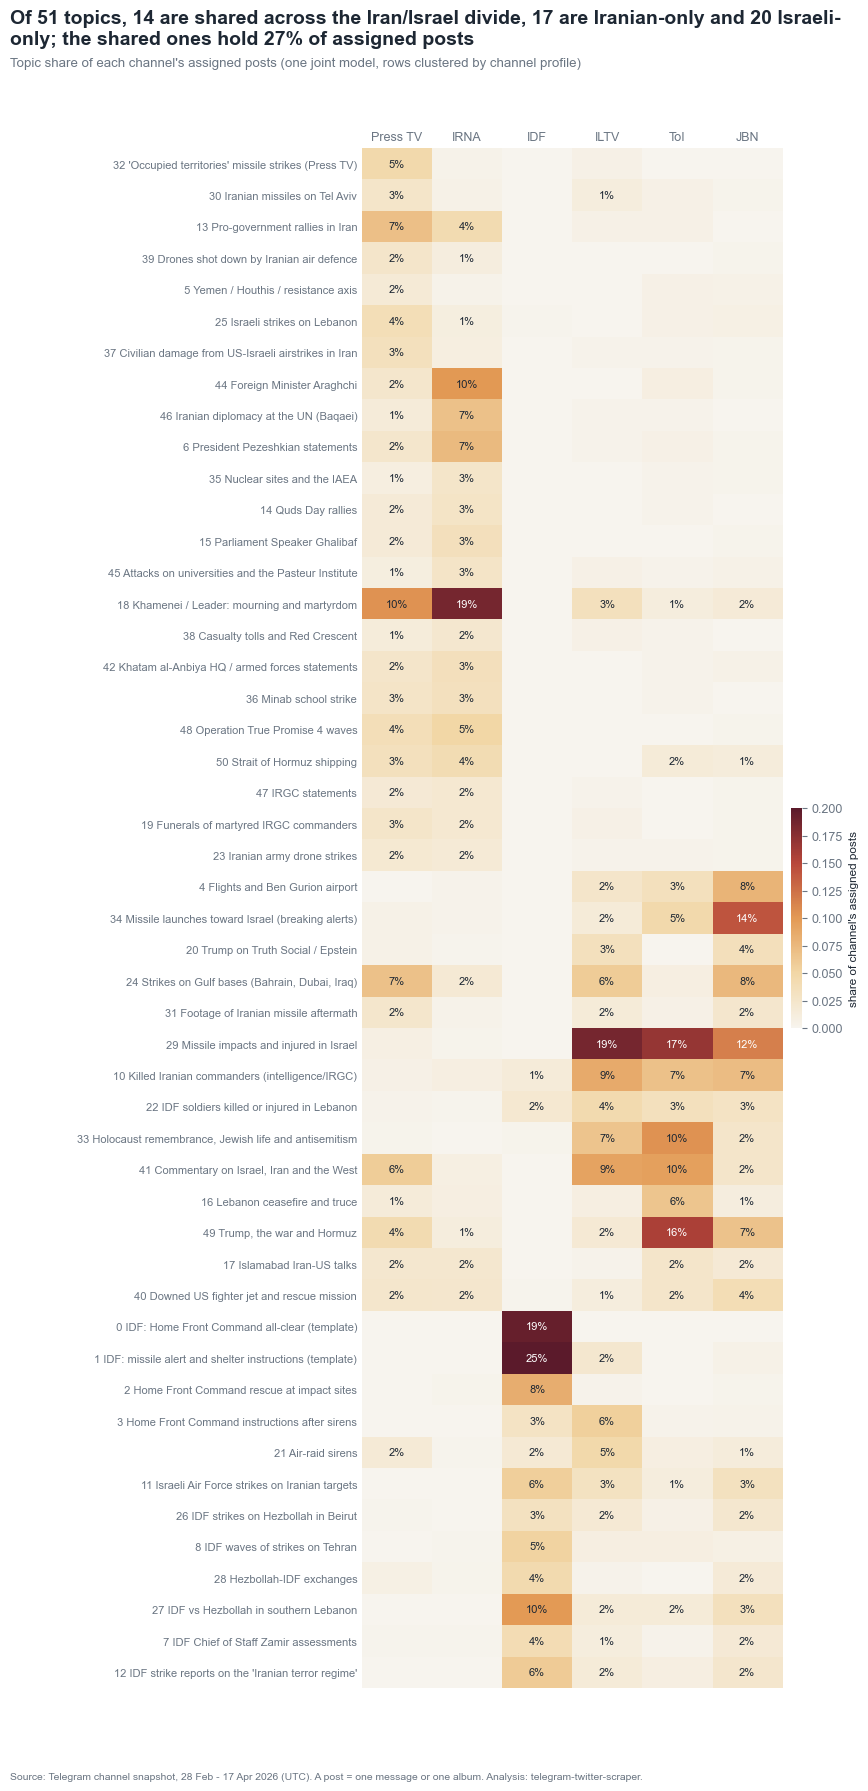

PosixPath('/Users/lfpmb/Documents/telegram-twitter-scraper/docs/study/interactive/03_topic_heatmap.html')

In [6]:
from scipy.cluster.hierarchy import linkage, leaves_list
prof = shares[shares["topic_id"] != -1].pivot(index="topic_id", columns="channel_slug", values="share_of_clustered").reindex(columns=CHANNEL_ORDER).fillna(0)
prof_n = prof.div(prof.sum(axis=1), axis=0)  # equal-weight channel profile of each topic (rows sum to 1)
prof["iran_weight"] = prof_n[["presstv", "irna-en"]].sum(axis=1)
prof["top_channel"] = prof_n.idxmax(axis=1)
prof["top_channel_weight"] = prof_n.max(axis=1)
sizes = summary.set_index("topic_id")["n"]
prof["n_posts"] = sizes
prof["label"] = [overrides[t] for t in prof.index]
def kind(r):
    if r["iran_weight"] >= 0.80: return "Iran-only"
    if r["iran_weight"] <= 0.20: return "Israel-only"
    return "shared across Iran/Israel"
prof["kind"] = prof.apply(kind, axis=1)
clustered_total = prof["n_posts"].sum()
by_kind = prof.groupby("kind").agg(topics=("label", "size"), posts=("n_posts", "sum"))
by_kind["share_of_clustered_posts"] = by_kind["posts"] / clustered_total
display(by_kind.round(3))

show = prof[prof[CHANNEL_ORDER].max(axis=1) >= 0.015]
order = leaves_list(linkage(prof_n.loc[show.index].to_numpy(), method="ward"))
show = show.iloc[order]
mat = show[CHANNEL_ORDER].rename(columns=SHORT_NAMES); mat.index = [f"{t:>2} {show.loc[t, 'label']}" for t in show.index]
h = 0.3 * len(mat) + 2.2
fig, ax = plt.subplots(figsize=(8.8, h))
fig.subplots_adjust(top=1 - 1.0 / h, bottom=0.5 / h, left=0.4)
viz.annotated_heatmap(ax, mat, fmt="{:.0%}", vmax=0.2, min_label=0.01, cbar_label="share of channel's assigned posts")
viz.color_channel_ticklabels(ax, axis="x"); ax.xaxis.tick_top(); ax.tick_params(axis="y", labelsize=8)
n_iran = int((prof["kind"] == "Iran-only").sum()); n_isr = int((prof["kind"] == "Israel-only").sum()); n_sh = int((prof["kind"] == "shared across Iran/Israel").sum())
viz.headline(fig, f"Of {len(prof)} topics, {n_sh} are shared across the Iran/Israel divide, {n_iran} are Iranian-only and {n_isr} Israeli-only; the shared ones hold {by_kind.loc['shared across Iran/Israel', 'share_of_clustered_posts']:.0%} of assigned posts",
             "Topic share of each channel's assigned posts (one joint model, rows clustered by channel profile)", y=1.0, wrap=95)
viz.done(fig, "03_topic_heatmap", shares.assign(label=shares["topic_label"]))
viz.export_data(prof.reset_index().rename(columns={"index": "topic_id"}), "03_topic_profiles")
viz.save(viz.plotly_heatmap(mat, title="Topic share by channel (joint model)", subtitle="share of each channel's assigned posts"), "03_topic_heatmap")

**Reading the figure.** The heat map splits cleanly into three blocks. Top (Iranian channels): Press TV and IRNA share rallies, True Promise waves, Minab, funerals and above all the Khamenei/Leader cluster (10% of Press TV's and 19% of IRNA's assigned posts); IRNA alone leans on diplomacy (Araghchi 10%, Pezeshkian 7%, UN/Baqaei 7%). Middle: the Israeli *news* channels (ILTV, ToI, JBN) concentrate on missile impacts and injured (19% / 17% / 12%), killed Iranian commanders (9% / 7% / 7%), Trump and the war (ToI 16%) and Holocaust/Jewish-life stories (ToI 10%, ILTV 7%). Bottom: the IDF is a different animal: its three alert and Home Front Command topics hold 52% of its assigned posts (25% + 19% + 8%), the remainder is Hezbollah and strike reports, and it shares almost nothing with the other Israeli channels except a sliver of strike and casualty topics. The Israeli private channels therefore resemble each other far more than any of them resembles the state-owned IDF.

By construction (every channel weighted equally), 40% of the assigned posts sit in Iran-only topics, 33% in Israel-only topics and 27% in topics both countries' channels write about.

## 5. Channel-specific vs shared topics

Each dot is a topic; "shared" means neither side holds more than 80% of its equal-weighted emphasis. Horizontal position is how the topic's weight splits between the two Iranian channels and the four Israeli ones (after giving every channel equal weight, so Press TV's volume does not drown the rest): 0 = only Israeli channels, 1 = only Iranian channels. Dot area is the topic's size.

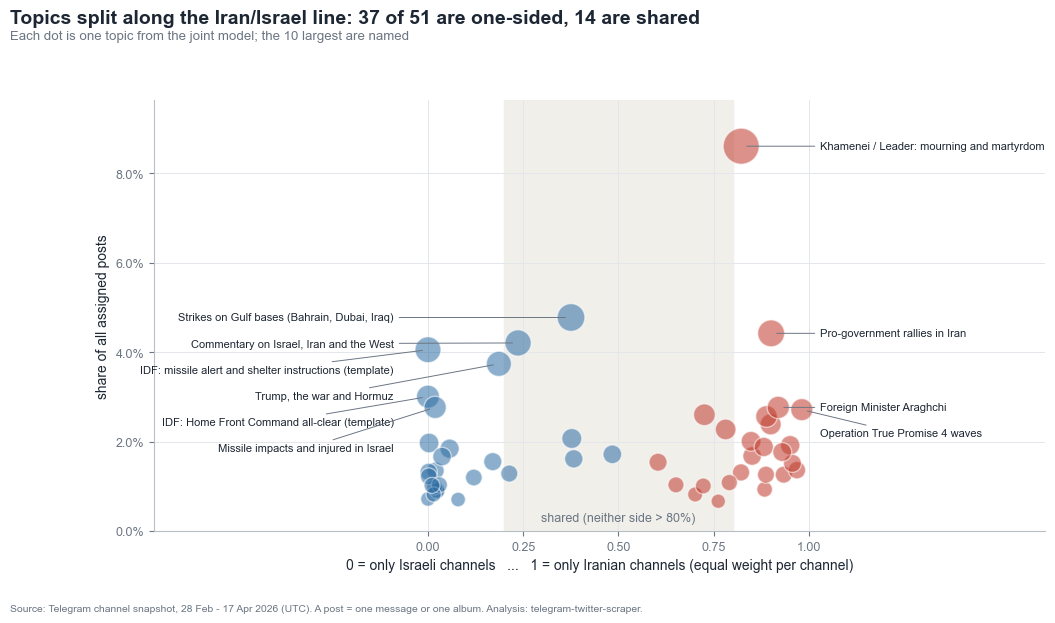

channel_slug,label,n_posts,iran_weight,top_channel,top_channel_weight,kind
topic_id,,,,,,
18,Khamenei / Leader: mourning and martyrdom,681,0.82,irna-en,0.53,Iran-only
24,"Strikes on Gulf bases (Bahrain, Dubai, Iraq)",378,0.38,jewishbreakingnewstelegram,0.33,shared across Iran/Israel
13,Pro-government rallies in Iran,350,0.90,presstv,0.56,Iran-only
41,"Commentary on Israel, Iran and the West",333,0.24,thetimesofisrael2022,0.34,shared across Iran/Israel
1,IDF: missile alert and shelter instructions (template),321,0.00,idfofficial,0.90,Israel-only
49,"Trump, the war and Hormuz",296,0.19,thetimesofisrael2022,0.53,Israel-only
0,IDF: Home Front Command all-clear (template),238,0.00,idfofficial,1.00,Israel-only
44,Foreign Minister Araghchi,219,0.92,irna-en,0.74,Iran-only
29,Missile impacts and injured in Israel,219,0.02,iltvnews,0.39,Israel-only


In [7]:
fig, ax = plt.subplots(figsize=(11.5, 5.6))
pf = prof.copy()
ypts = pf["n_posts"] / clustered_total
colors = pf["iran_weight"].map(lambda w: viz.COUNTRY_COLORS["Iran"] if w >= 0.5 else viz.COUNTRY_COLORS["Israel"])
ax.axvspan(0.20, 0.80, color="#F0EFEA", zorder=0)
ax.scatter(pf["iran_weight"], ypts, s=60 + pf["n_posts"] * 0.9, color=colors, alpha=0.55, edgecolor="white", linewidth=1, zorder=3)
ax.set_xlim(-0.72, 1.62); ax.set_ylim(0.0, ypts.max() * 1.12)
ax.text(0.5, ax.get_ylim()[0] + 0.0015, "shared (neither side > 80%)", ha="center", va="bottom", color=viz.MUTED, fontsize=9, zorder=2)
# Labels sit in two side columns with leader lines, spaced so they can never overlap.
top = pf.assign(y=ypts).sort_values("n_posts", ascending=False).head(10)
gap = ypts.max() * 0.068
for side, sub in (("left", top[top["iran_weight"] < 0.5]), ("right", top[top["iran_weight"] >= 0.5])):
    sub = sub.sort_values("y", ascending=False)
    pos, last = [], None
    for y in sub["y"]:
        last = y if last is None else min(y, last - gap)
        pos.append(last)
    for (tid, r), ty in zip(sub.iterrows(), pos):
        x_text = -0.09 if side == "left" else 1.03
        ax.annotate(r["label"], (r["iran_weight"], r["y"]), xytext=(x_text, ty), textcoords="data", ha="right" if side == "left" else "left", va="center", fontsize=8,
                    color=viz.INK, arrowprops={"arrowstyle": "-", "color": viz.MUTED, "lw": 0.7, "shrinkA": 2, "shrinkB": 4}, zorder=4)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1]); ax.set_xlabel("0 = only Israeli channels   ...   1 = only Iranian channels (equal weight per channel)")
ax.set_ylabel("share of all assigned posts"); ax.yaxis.set_major_formatter(PercentFormatter(1.0))
viz.headline(fig, f"Topics split along the Iran/Israel line: {n_iran + n_isr} of {len(prof)} are one-sided, {n_sh} are shared", "Each dot is one topic from the joint model; the 10 largest are named", y=1.01)
viz.done(fig, "03_topic_specificity", prof.reset_index().rename(columns={"index": "topic_id"}))
display(prof.sort_values("n_posts", ascending=False)[["label", "n_posts", "iran_weight", "top_channel", "top_channel_weight", "kind"]].head(15).round(2))

**Reading the figure.** The largest topics are one-sided. The Khamenei/Leader cluster (681 posts) is classed Iran-only, together with rallies, Araghchi and True Promise; IDF alert templates and missile-impact reports sit at the Israeli end. The shared middle holds the strikes on Gulf bases (378 posts, with JBN 8%, Press TV 7%, ILTV 6% of assigned posts), commentary on Israel, Iran and the West (333), Strait of Hormuz shipping (206), Islamabad talks (136) and the downed US fighter jet (164): the events everyone had to cover. "Shared" here means neither side accounts for more than 80% of the topic's equal-weighted emphasis, a deliberately modest bar.

## 6. A map of all posts

Every post as a point in the two-dimensional UMAP layout of the embeddings, coloured by channel. Overlap means the channels write about the same things; separate islands mean topics only one side covers.

1114 of 11,931 posts fall outside the cropped view (745 of them IDF, mostly near-identical alert templates)


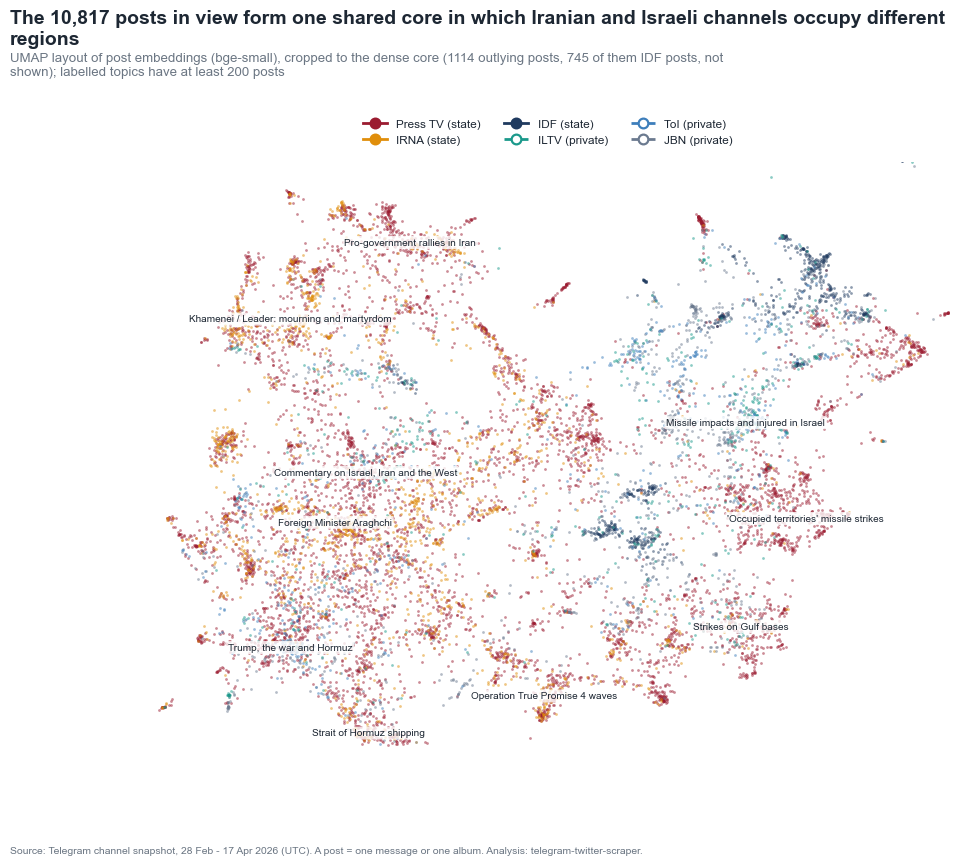

In [8]:
coords = assign[["x2d", "y2d"]].to_numpy()
cent = {}
for t, g in assign[assign["topic_id"] != -1].groupby("topic_id"):
    if len(g) >= 200:
        cent[t] = (g["x2d"].median(), g["y2d"].median(), overrides[t].split(" (")[0][:46])
lo, hi = np.percentile(coords, 4, axis=0), np.percentile(coords, 96, axis=0)   # robust limits: the far-away islands are near-identical IDF alert templates
pad = (hi - lo) * 0.06
xlim, ylim = (lo[0] - pad[0], hi[0] + pad[0]), (lo[1] - pad[1], hi[1] + pad[1])
inside = (coords[:, 0] >= xlim[0]) & (coords[:, 0] <= xlim[1]) & (coords[:, 1] >= ylim[0]) & (coords[:, 1] <= ylim[1])
cent = {t_: v for t_, v in cent.items() if xlim[0] <= v[0] <= xlim[1] and ylim[0] <= v[1] <= ylim[1]}
fig, ax = plt.subplots(figsize=(10.5, 7.6))
viz.umap_map(ax, coords, assign["channel_slug"].to_numpy(), labels=cent, point_size=4, alpha=0.5)
ax.set_xlim(*xlim); ax.set_ylim(*ylim)
viz.channel_legend(ax, loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3, fontsize=8.5)
outside = int((~inside).sum()); idf_out = int((~inside & (assign["channel_slug"] == "idfofficial").to_numpy()).sum())
print(f"{outside} of {len(coords):,} posts fall outside the cropped view ({idf_out} of them IDF, mostly near-identical alert templates)")
viz.headline(fig, f"The {int(inside.sum()):,} posts in view form one shared core in which Iranian and Israeli channels occupy different regions", f"UMAP layout of post embeddings (bge-small), cropped to the dense core ({outside} outlying posts, {idf_out} of them IDF posts, not shown); labelled topics have at least 200 posts", y=1.03, wrap=100)
viz.done(fig, "03_umap_map", assign[["post_id", "channel_slug", "x2d", "y2d", "topic_id", "topic_label"]])
hover = assign.assign(preview=assign["short_name"] + " " + assign["timestamp"].dt.strftime("%m-%d") + ": " + assign["clean_text"].str.slice(0, 110).str.replace("<", "(") + "<br>" + assign["topic_label"])
viz.save(viz.plotly_umap(coords, hover, title="Map of all posts", subtitle="Hover for the post and its topic"), "03_umap_map")
assign[["post_id", "topic_id", "topic_label", "probability", "x2d", "y2d"]].to_parquet(study.CACHE_DIR / "topic_assignments.parquet", index=False)

**Reading the figure.** One dense, overlapping core in which all six colours mix, but the colours occupy different regions of it: the Iranian material (rallies, official statements, Khamenei items, True Promise waves) fills the left and lower part, and the Israeli casualty, impact and alert reports gather toward the upper right, with the IDF's communiqués forming their own tight clumps in that region. The view is cropped to the central 92% of points on each axis: 1,114 of the 11,931 posts fall outside it, 745 of them IDF posts, because the IDF's near-identical alert templates sit in tiny far-away islands that would otherwise stretch the map. The picture supports "same war, different framing of it", not "different worlds".

## 7. Commemoration: a symmetric test of the "state legitimacy work" claim

The first-pass article read a large Khamenei memorial cluster in Press TV as a fingerprint of state broadcasting doing legitimacy work. That inference only holds if private or Israeli channels do *not* produce equivalent commemoration. So the same question is asked symmetrically with two keyword families, each applied to every channel (posts with text, Wilson 95% intervals):

- **(a) Khamenei / Supreme Leader mourning**: mourning, martyrdom, funeral, condolence, memorial or 40th-day language within the same sentence stretch as Khamenei / the Leader of the Islamic Revolution.
- **(b) Israeli national commemoration**: Yom HaShoah / Holocaust Remembrance, Memorial Day / Yom HaZikaron / Remembrance Day, memorial ceremonies, "May his memory be a blessing", and October 7 memorial language.

Precision is checked below by printing matches.

In [9]:
LEADER = r"Khamenei|Supreme Leader|Leader of the (?:Islamic )?Revolution|(?:the )?late Leader|Imam Khamenei"
MOURN = r"mourn|martyr|funeral|condolence|memorial|commemorat|40th day|fortieth|procession|pays? (?:tribute|respects)|bereave"
PAT_A = rf"(?:{MOURN}).{{0,140}}(?:{LEADER})|(?:{LEADER}).{{0,140}}(?:{MOURN})"
PAT_B = (r"Yom Ha-?Shoah|Holocaust (?:Remembrance|survivor|memorial|Day)|Memorial Day|Yom Ha-?Zikaron|Remembrance Day|Zikaron|"
         r"fallen (?:soldiers|heroes)|soldiers? fell in battle|may (?:his|her|their) memory be|"
         r"(?:Oct(?:ober|\.)?|October) 7.{0,60}(?:memorial|commemorat|remember|victims)|(?:memorial|commemorat|remember).{0,60}(?:Oct(?:ober|\.)?|October) 7")
tx = posts[posts["has_clean_text"]].copy()
tx["comm_a"] = tx["clean_text"].str.contains(PAT_A, case=False, regex=True)
tx["comm_b"] = tx["clean_text"].str.contains(PAT_B, case=False, regex=True)
comm = pd.concat([stats.share_table(tx, "channel_slug", "comm_a").assign(measure="(a) Khamenei mourning"),
                  stats.share_table(tx, "channel_slug", "comm_b").assign(measure="(b) Israeli national commemoration")], ignore_index=True)
comm["channel"] = comm["channel_slug"].map(SHORT_NAMES)
display(comm.pivot(index="channel", columns="measure", values=["successes", "share"]).reindex([SHORT_NAMES[s] for s in CHANNEL_ORDER]).round(4))
for col, name in (("comm_a", "(a)"), ("comm_b", "(b)")):
    print("=" * 90); print(name, "sample matches (one per channel with matches):")
    for slug in CHANNEL_ORDER:
        m = tx[(tx["channel_slug"] == slug) & tx[col]]
        if len(m): print(f"  {SHORT_NAMES[slug]:>8} ({len(m)}): {m['clean_text'].iloc[len(m) // 2][:140]!r}")

successes                                                    share                                   
measure  (a) Khamenei mourning (b) Israeli national commemoration (a) Khamenei mourning (b) Israeli national commemoration
channel                                                                                                                   
Press TV                 188.0                                0.0                0.0284                             0.0000
IRNA                     201.0                                1.0                0.1229                             0.0006
IDF                        0.0                               14.0                0.0000                             0.0098
ILTV                       1.0                               18.0                0.0018                             0.0332
ToI                        0.0                               10.0                0.0000                             0.0161
JBN                        1.0                               11.0                0.0009                             0.0099

(a) sample matches (one per channel with matches):
  Press TV (188): 'Ayatollah Mojtaba Khamenei endorses officials appointed by martyred Leader\n\nLeader of the Islamic Revolution Ayatollah Seyyed Mojtaba\u202fKhamen'
      IRNA (201): 'Muslims in Washington pay tribute to Martyr Ayatollah Khamenei\n\nMany Iranians, cultural and religious figures, as well as Muslims from vario'
      ILTV (1): 'North Korea appears to be distancing itself from Iran and keeping its public messaging cautious following the war, according to South Korean'
       JBN (1): "JUST IN: The Iranian government and IRGC has declared 40 days of public mourning following the official confirmation of Ali Khamenei's death"
(b) sample matches (one per channel with matches):
      IRNA (1): 'Army chief warns of decisive response to any aggression after Isfahan attack\n\nChief Commander of Iran’s Army Major General Amir Hatami has w'
       IDF (14): 'In the incident in which Staff Sergeant Gilad Harel fell, Captain Noam

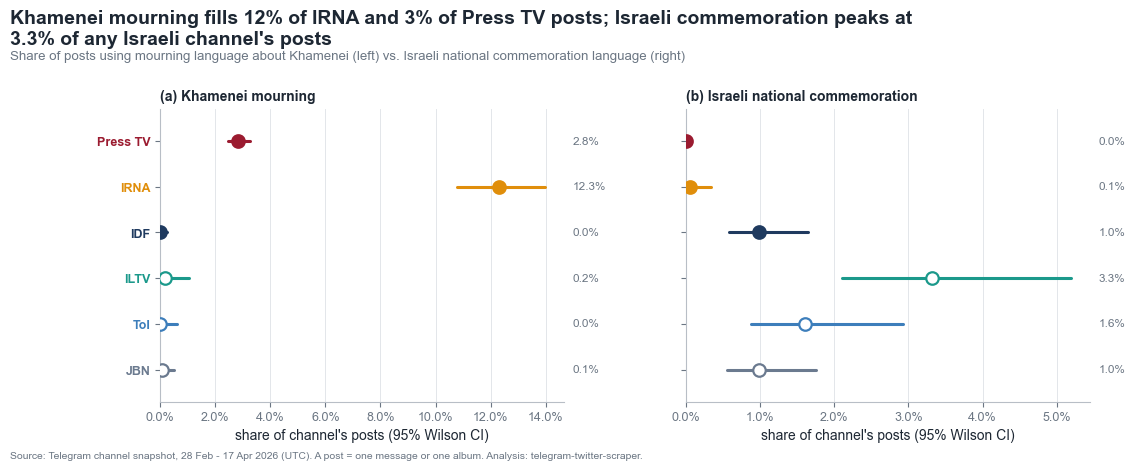

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True, gridspec_kw={"wspace": 0.3})
for ax, (measure, sub) in zip(axes, comm.groupby("measure", sort=False)):
    sub = sub.set_index("channel_slug").reindex(CHANNEL_ORDER).reset_index()
    viz.dot_whisker(ax, sub, label_col="channel", est_col="share", lo_col="ci_low", hi_col="ci_high", value_fmt="{:.1%}", xlabel="share of channel's posts (95% Wilson CI)")
    ax.set_title(measure, fontsize=10); ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.set_xlim(left=0)
a = comm[comm["measure"].str.startswith("(a)")].set_index("channel_slug"); b = comm[comm["measure"].str.startswith("(b)")].set_index("channel_slug")
viz.headline(fig, f"Khamenei mourning fills {a.loc['irna-en', 'share']:.0%} of IRNA and {a.loc['presstv', 'share']:.0%} of Press TV posts; Israeli commemoration peaks at {b.loc[['idfofficial','iltvnews','thetimesofisrael2022','jewishbreakingnewstelegram'], 'share'].max():.1%} of any Israeli channel's posts",
             "Share of posts using mourning language about Khamenei (left) vs. Israeli national commemoration language (right)", y=1.04, wrap=95)
viz.done(fig, "03_commemoration", comm)

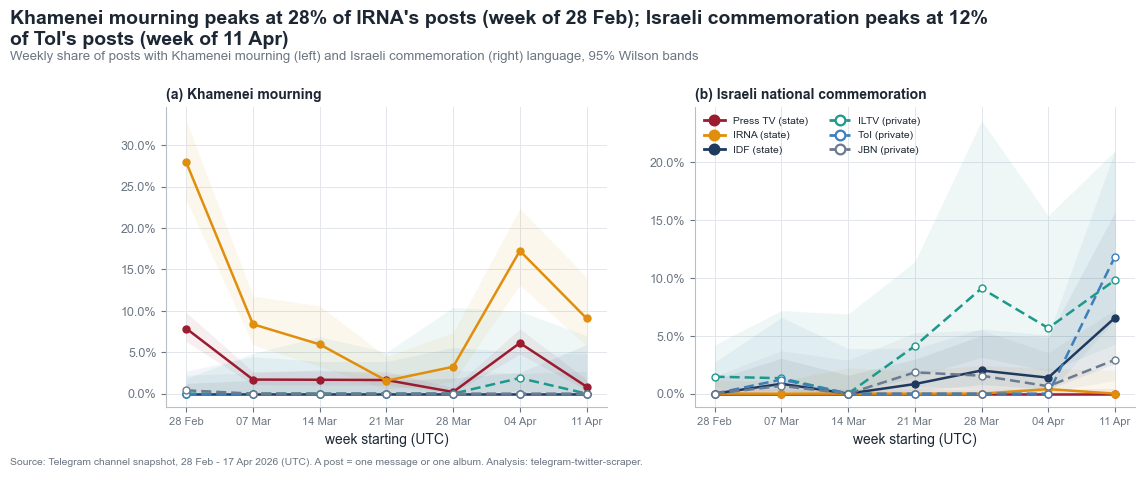

In [11]:
tx["week"] = ((tx["timestamp"] - WINDOW[0]).dt.days // 7).astype(int)
week_start = {w: (WINDOW[0] + pd.Timedelta(days=7 * w)) for w in range(7)}
rows = []
for col, measure in (("comm_a", "(a) Khamenei mourning"), ("comm_b", "(b) Israeli national commemoration")):
    for week, g in tx.groupby("week"):
        t = stats.share_table(g, "channel_slug", col)
        t["week"] = week; t["week_start"] = week_start[week].strftime("%d %b"); t["measure"] = measure
        rows.append(t)
weekly = pd.concat(rows, ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), sharex=True)
for ax, (measure, sub) in zip(axes, weekly.groupby("measure", sort=False)):
    for slug in CHANNEL_ORDER:
        s = sub[sub["channel_slug"] == slug].sort_values("week"); st = viz.style(slug)
        ax.plot(s["week"], s["share"], color=st["color"], ls=st["linestyle"], marker="o", ms=5, mfc=st["markerfacecolor"], lw=1.8)
        ax.fill_between(s["week"], s["ci_low"], s["ci_high"], color=st["color"], alpha=0.07, linewidth=0)
    ax.set_title(measure, fontsize=10); ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xticks(range(7)); ax.set_xticklabels([week_start[w].strftime("%d %b") for w in range(7)], fontsize=8)
    ax.set_xlabel("week starting (UTC)")
viz.channel_legend(axes[1], ncol=2, loc="upper left", fontsize=7.5)
wk = weekly[weekly["measure"].str.startswith("(a)")].query("channel_slug in ['presstv','irna-en']").sort_values("share").iloc[-1]
wb = weekly[weekly["measure"].str.startswith("(b)")].query("channel_slug in ['idfofficial','iltvnews','thetimesofisrael2022','jewishbreakingnewstelegram']").sort_values("share").iloc[-1]
viz.headline(fig, f"Khamenei mourning peaks at {wk['share']:.0%} of {SHORT_NAMES[wk['channel_slug']]}'s posts (week of {wk['week_start']}); Israeli commemoration peaks at {wb['share']:.0%} of {SHORT_NAMES[wb['channel_slug']]}'s posts (week of {wb['week_start']})",
             "Weekly share of posts with Khamenei mourning (left) and Israeli commemoration (right) language, 95% Wilson bands", y=1.03, wrap=100)
viz.done(fig, "03_commemoration_weekly", weekly)

**Reading the figures.** The symmetric test gives a clear and slightly awkward answer for the first-pass claim.

- *(a) Khamenei mourning language* is **12.3% of IRNA posts (10.8-14.0%) and 2.8% of Press TV posts (2.5-3.3%)**; at the IDF, ToI, ILTV and JBN it is 0-0.2%. IRNA's use is four times Press TV's, so the two Iranian state outlets do not share one fingerprint.
- *(b) Israeli national commemoration language* (Holocaust Remembrance, Memorial Day, "fallen soldiers", "may his memory be a blessing", Oct 7 memorials) is **3.3% of ILTV posts (2.1-5.2%), 1.6% of ToI, 1.0% of JBN and 1.0% of the IDF**; Press TV has none and IRNA one post.
- Over time both are event-driven: IRNA's mourning share is 28% in the first week (28 Feb-6 Mar; Press TV 7.9%), falls to 1.6% by late March and returns to 17% in the week of the 40th day (4-10 Apr; Press TV 6.1%). Israeli commemoration is near zero until late March and peaks in the last week (11-17 Apr: ToI 11.8%, ILTV 9.8%, IDF 6.6%, JBN 2.9%), the week of Yom HaShoah.
- Topic-level cross-check: the Khamenei/Leader topic is 18.6% of IRNA's and 10.4% of Press TV's assigned posts; the Holocaust/Jewish-life topic is 10.4% of ToI's and 6.5% of ILTV's. Press TV's memorial-topic share is exactly that of the private newspaper's Holocaust topic.

So the first-pass inference does not survive. Commemoration of nationally central dead is present on both sides and in both ownership types; what differs is *whose* dead, and (for IRNA) the weight. A weaker, defensible version is available: Iranian state media devote more of their output to mourning their own leader (IRNA 12%) than any Israeli channel devotes to its commemorations (at most 3.3%), but the keyword families are not equivalent measures, so the size comparison between (a) and (b) is suggestive only. (Keyword matching has errors too: the single ILTV and JBN matches for (a) are news reports of Iran's declared mourning, not mourning by the channel.)

In [12]:
t18 = shares[shares["topic_id"] == 18].set_index("channel_slug").reindex(CHANNEL_ORDER)
t33 = shares[shares["topic_id"] == 33].set_index("channel_slug").reindex(CHANNEL_ORDER)
check = pd.DataFrame({"khamenei_topic_share_of_assigned": t18["share_of_clustered"], "holocaust_topic_share_of_assigned": t33["share_of_clustered"]})
display(check.rename(index=SHORT_NAMES).round(4))
_ = study.record_findings("03_agenda", {
    "n_posts_in_model": int(len(topic_df)), "min_words": MIN_WORDS, "embedding_model": embedder.model_name,
    "grid": grid, "selection_rule": "mean ARI >= 0.5, 20 <= topics <= 60, then lowest noise share (20-topic floor added after the 120 setting collapsed to 3-4 topics)",
    "chosen_config": {"min_cluster_size": MCS, "min_samples": config.min_samples, "umap_neighbors": config.umap_neighbors, "cluster_dims": config.cluster_dims, "random_state": config.random_state},
    "mean_ari": float(chosen["mean_ari"]), "min_ari": float(chosen["min_ari"]), "unstable": bool(unstable),
    "n_topics": int(joint.n_topics), "noise_share": float((assign["topic_id"] == -1).mean()),
    "noise_share_by_channel": joint.noise_share_by_group.set_index("channel_slug")["share"],
    "topic_kinds": by_kind.reset_index(),
    "topic_profiles": prof.reset_index().rename(columns={"index": "topic_id"})[["topic_id", "label", "n_posts", "iran_weight", "top_channel", "top_channel_weight", "kind"]],
    "commemoration_shares": comm.drop(columns="channel"),
    "commemoration_weekly": weekly[["measure", "channel_slug", "week", "week_start", "n", "successes", "share", "ci_low", "ci_high"]],
    "commemoration_patterns": {"a": PAT_A, "b": PAT_B},
    "topic_cross_check": check.reset_index(),
})

,khamenei_topic_share_of_assigned,holocaust_topic_share_of_assigned
channel_slug,,
Press TV,0.1042,0.0021
IRNA,0.1856,0.0000
IDF,0.0000,0.0016
ILTV,0.0341,0.0650
ToI,0.0123,0.1043
JBN,0.0163,0.0245


## What this means for the article

- **Drop "Khamenei memorial cluster = state-broadcaster fingerprint".** Say instead: *Iranian state outlets spent a visible share of the war's output on mourning Khamenei (IRNA 12%, Press TV 3% of posts mention mourning him; 10-19% of assigned posts sit in the broader Khamenei/Leader topic), and Israeli channels did the equivalent for their own national commemorations (1-3% of posts, 7-12% of weekly output in the week of Yom HaShoah).*
- **Do not attribute differences to ownership** from topic data: the clean split in this notebook is by *country* and, inside Israel, IDF (state) vs the three private channels.
- **Quote shared coverage as well as differences**: about a quarter of assigned posts are in topics both countries' channels cover (Gulf strikes, Hormuz, Islamabad talks, Trump and the war).
- **Caveat**: topic labels are hand-written summaries of keyword clusters; one third of posts are unassigned; the IDF's topic profile is mostly alert templates.